# **WIH2001 Data Analytics**

###**Group Assignment 2: Predictive Modeling & Research Benchmarking**

**TEAM MEMBERS (GROUP 3):**
1. AQASYAH FATIN AFRINA BINTI MOKHTAR (23002750)
2. DHANIA NAFEESA BINTI MOHD DZULKAEDAH (23002157)
3. NUR IMAN BATRISYIA BINTI HUSNI RIZAL (23001812)
4. SANJEEVAN A/L KUMARESON (23109697)
5. TANISH RAJAH (23109229)

**TOPIC:**

BENCHMARKING MACHINE LEARNING MODELS AGAINST ARIMA FOR RON97 FUEL PRICE FORECASTING IN MALAYSIA

**CONTINUITY OF ASSIGNMENT 1:**

TREND AND PATTERN ANALYSIS OF PETROLEUM AND DIESEL PRICES IN MALAYSIA (BY NUR IMAN BATRISYIA)

# **Section 1: Executive Summary**
## **1.1 Problem Statement**

Fuel prices in Malaysia are a critical macroeconomic driver influencing household spending, corporate logistics costs, and national inflation. While regulated fuels (RON95 and Diesel) operate under government price caps, RON97 floats freely based on international market factors (global crude oil fluctuations, refining margins, and exchange rates). This lack of subsidy exposure introduces high price volatility.
Building upon our initial data exploration in Assignment 1, which established a cleaned weekly dataset from Malaysia's Official Open Data Portal (data.gov.my), this study transitions from descriptive analysis to a full predictive modeling pipeline. We target RON97 as our primary forecasting variable to assist businesses and consumers in financial planning.

## **1.2 Research Baseline**

To benchmark our machine learning models, we target a recent peer-reviewed study by Syakinah & Noreha (2025): "Forecasting The Price of Research Octane Number 97 (RON97) In Malaysia: A Box-Jenkins Approach" (MJII, Vol. 4, Issue 6).
- Methodology: The authors applied a univariate Box-Jenkins ARIMA(1,1,1) model on monthly RON97 data from January 2020 to January 2024.
- Baseline Forecast: The study projected a 24-month out-of-sample price corridor between RM 3.37 and RM 3.62 for the period spanning February 2024 to January 2026.


### **Baseline Limitations Addressed by Our Group**
**Strictly Univariate:** The ARIMA model relies solely on past RON97 values to generate forecasts, and does not incorporate external variables such as RON95 or Diesel prices.

- To ensure a fair Phase 1 comparison, we adopt the same constraint. However unlike ARIMA, our ML models are architecturally capable of incorporating multiple features, which we exploit in Phase 2.

**No Absolute Error Metrics Reported:** The authors relied entirely on relative fit statistics (AIC=−217.11, BIC=−211.97) without reporting standard forecasting metrics such as RMSE, MAE, or R².
- Our replication fills this gap directly.

**Pandemic-Dominated Opening Window:** The study's dataset begins in January 2020, coinciding with the onset of COVID-19 disruptions.

- Our preprocessing isolates the same January 2020 – January 2024 window to match the baseline faithfully, resampled from weekly to monthly frequency to ensure temporal consistency.


## **1.3 Study Structure**

**This study is structured in two phases:**
- **Phase 1 — Univariate Analysis:**
A direct and fair comparison between our ML models and the ARIMA(1,1,1) baseline using RON97 data only, over the same evaluation period as Syakinah & Noreha (2025).

- **Phase 2 - Multivariate Analysis:**
The feature space is extended to include government-regulated fuel prices (ron95 and diesel) as macro-structural anchors. Phase 2 is conducted only after Phase 1 confirms our models outperform the ARIMA baseline.

## **1.4 Group Hypothesis**

We hypothesize that supervised machine learning models (Ridge Regression and Support Vector Regression) will outperform the classical linear ARIMA(1,1,1) baseline when evaluated across the same 9-month holdout test set.

### **Rationale**
**Ridge Regression:** Provides a regularized linear alternative to ARIMA, penalizing coefficient magnitude to reduce overfitting on the small 45-month dataset while remaining interpretable.

**Support Vector Regression:** It does not assume linearity or stationarity and uses an epsilon-insensitive loss function well-suited to the low-volatility, high-inertia nature of regulated fuel price series.

**Multivariate Capability:** Both models can natively incorporate cross-fuel features in Phase 2, an architectural advantage ARIMA structurally cannot match.

### **Definition of Success**
A successful outcome is defined as achieving a lower RMSE and MAE and higher R² than the ARIMA(1,1,1) baseline on the test period. If our models initially underperform, we will systematically document our iterative hyperparameter tuning process as part of our analytical contribution.


**References**

**Dataset Source:** Malaysia Official Open Data Portal — Price of Petroleum and Diesel in Malaysia (data.gov.my)

**Baseline Reference:** Zaki, N.S.M. & Yusof, N.M. (2025). Forecasting The Price of Research Octane Number 97 (RON97) In Malaysia: A Box-Jenkins Approach. Malaysia Journal of Invention and Innovation (MJII), 4(6). DOI: 10.5281/zenodo.15789499


# **Section 2: Data Cleaning, Resampling & Feature Engineering**

In [ ]:
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')
PROJECT_PATH = '/content/drive/MyDrive/Data_Analytics_Project/'
df = pd.read_csv(PROJECT_PATH + 'originalfuelprice.csv')

df_cleaned = df.drop(columns=['ron95_budi95'])
df_preprocessed = df_cleaned[df_cleaned['series_type'] == 'level'].copy()
df_preprocessed['date'] = pd.to_datetime(df_preprocessed['date'])
df_preprocessed = df_preprocessed.drop_duplicates()
df_preprocessed = df_preprocessed.drop(columns=['series_type'])

df_filtered = df_preprocessed[
    (df_preprocessed['date'] >= '2020-01-01') &
    (df_preprocessed['date'] <= '2024-01-31')
].copy()

df_filtered = df_filtered.set_index('date')
df_monthly = df_filtered.resample('ME').mean(numeric_only=True).reset_index()

df_ron97 = df_monthly.copy()
df_ron97['ron97_lag1'] = df_ron97['ron97'].shift(1)
df_ron97['ron97_lag2'] = df_ron97['ron97'].shift(2)
df_ron97['ron97_lag3'] = df_ron97['ron97'].shift(3)
df_ron97['target_ron97_next_month'] = df_ron97['ron97'].shift(-1)
df_ron97_clean = df_ron97.dropna().copy()
df_all_fuels = df_monthly.copy()

df_ron97_clean.to_csv(PROJECT_PATH + 'df_ron97_clean_newest.csv', index=False)
df_all_fuels.to_csv(PROJECT_PATH + 'df_all_fuels_newest.csv', index=False)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# **Section 3: Exploratory Data Analysis (EDA)**

In [ ]:
df = pd.read_csv(PROJECT_PATH + "df_ron97_clean_newest.csv")
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date')
df.head()

,date,ron95,ron97,diesel,diesel_eastmsia,ron97_lag1,ron97_lag2,ron97_lag3,target_ron97_next_month
0,2020-04-30,1.2625,1.5625,1.4675,1.4675,1.9275,2.3780,2.5725,1.6240
1,2020-05-31,1.3240,1.6240,1.4740,1.4740,1.5625,1.9275,2.3780,1.8800
2,2020-06-30,1.5800,1.8800,1.7475,1.7475,1.6240,1.5625,1.9275,1.9925
3,2020-07-31,1.6925,1.9925,1.8500,1.8500,1.8800,1.6240,1.5625,1.9840
4,2020-08-31,1.6840,1.9840,1.8040,1.8040,1.9925,1.8800,1.6240,1.9700


### **Monthly RON 97 Time Series Plot with Covid-19 Dip**


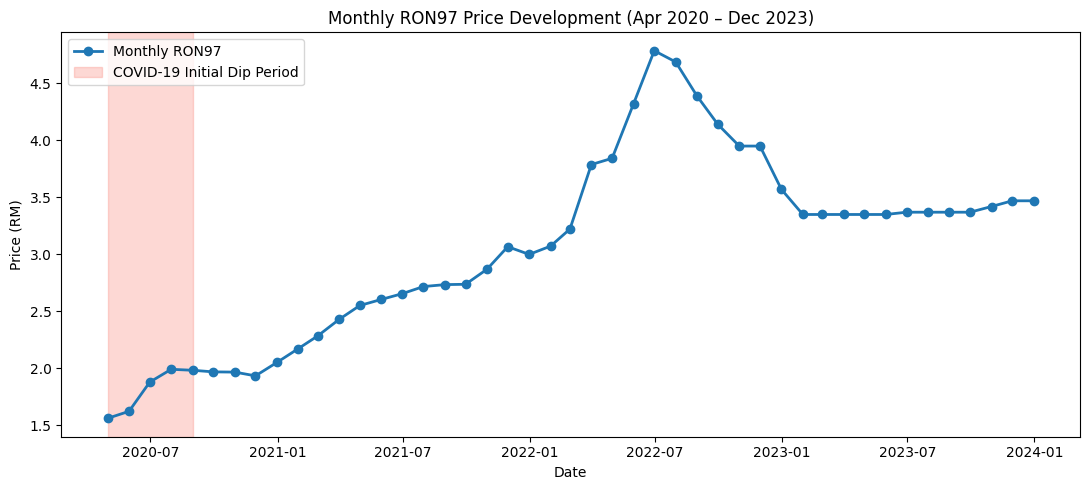

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 5))
plt.plot(df['date'], df['ron97'], marker='o', color='#1f77b4', linewidth=2, label='Monthly RON97')

# Highlight the COVID-19 initial dip (from April 2020 - August 2020)
plt.axvspan(pd.to_datetime('2020-04-30'), pd.to_datetime('2020-08-31'),
            color='salmon', alpha=0.3, label='COVID-19 Initial Dip Period')

plt.title('Monthly RON97 Price Development (Apr 2020 – Dec 2023)')
plt.xlabel('Date')
plt.ylabel('Price (RM)')
plt.legend(loc='upper left')
plt.tight_layout()
plt.savefig('ron97_time_series_covid.png', dpi=300)
plt.show()

### **Correlation Heatmap**

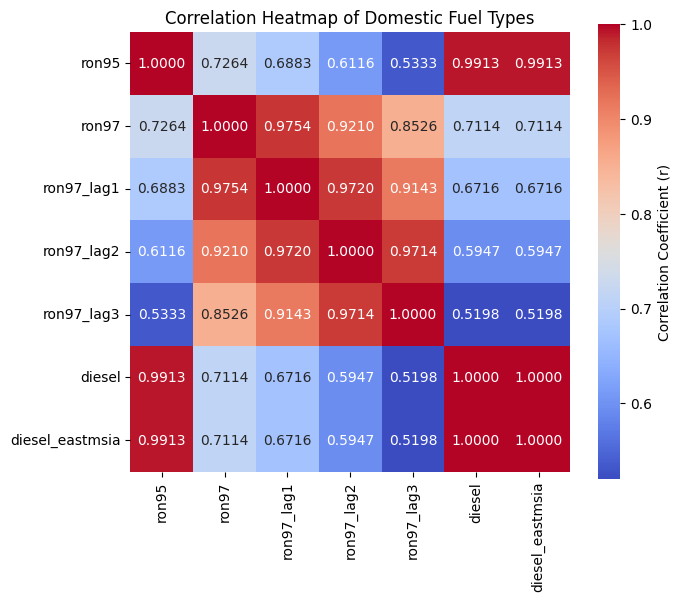

In [ ]:
import seaborn as sns

fuel_cols = ['ron95', 'ron97', 'ron97_lag1', 'ron97_lag2', 'ron97_lag3', 'diesel', 'diesel_eastmsia']
corr_matrix = df[fuel_cols].corr()

plt.figure(figsize=(7, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".4f", square=True,
            cbar_kws={'label': 'Correlation Coefficient (r)'})

plt.title('Correlation Heatmap of Domestic Fuel Types')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=300)
plt.show()

- Diesel in Peninsular Malaysia and Diesel in East Malaysia are **perfectly correlated**, showing that the price movements is strongly alligned
- RON97 has high correlation with its lagged values, indicates that past RON97 prices are excellent predictors of current price

### **3-month Rolling Average**

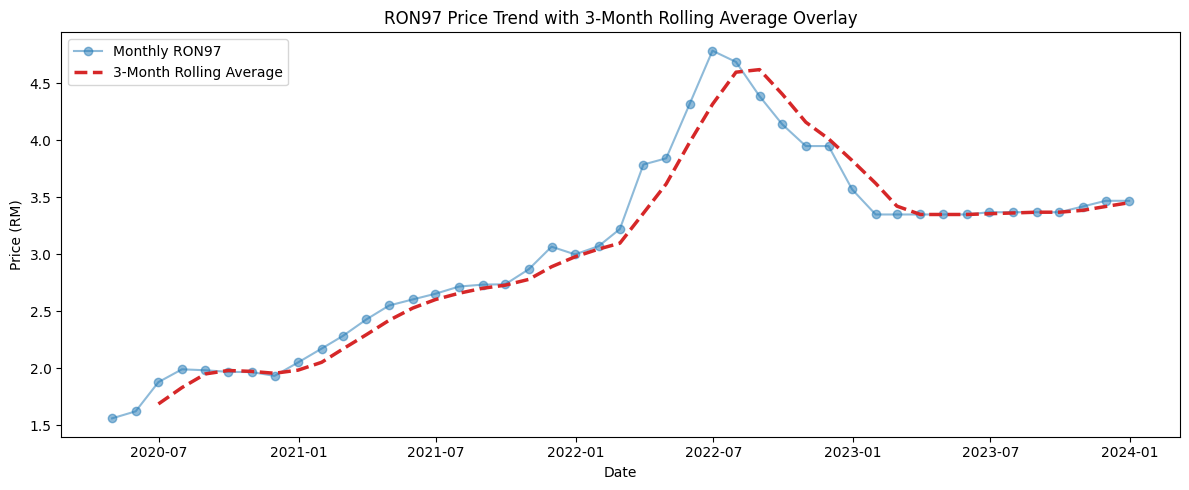

In [ ]:
df['ron97_rolling_3m'] = df['ron97'].rolling(window=3).mean()

plt.figure(figsize=(12, 5))
plt.plot(df['date'], df['ron97'], marker='o', alpha=0.5, color='#1f77b4', label='Monthly RON97')
plt.plot(df['date'], df['ron97_rolling_3m'], linestyle='--', color='#d62728', linewidth=2.5, label='3-Month Rolling Average')

plt.title('RON97 Price Trend with 3-Month Rolling Average Overlay')
plt.xlabel('Date')
plt.ylabel('Price (RM)')
plt.legend(loc='upper left')
plt.tight_layout()
plt.savefig('ron97_rolling_average.png', dpi=300)
plt.show()

### **Histogram and Boxplots**

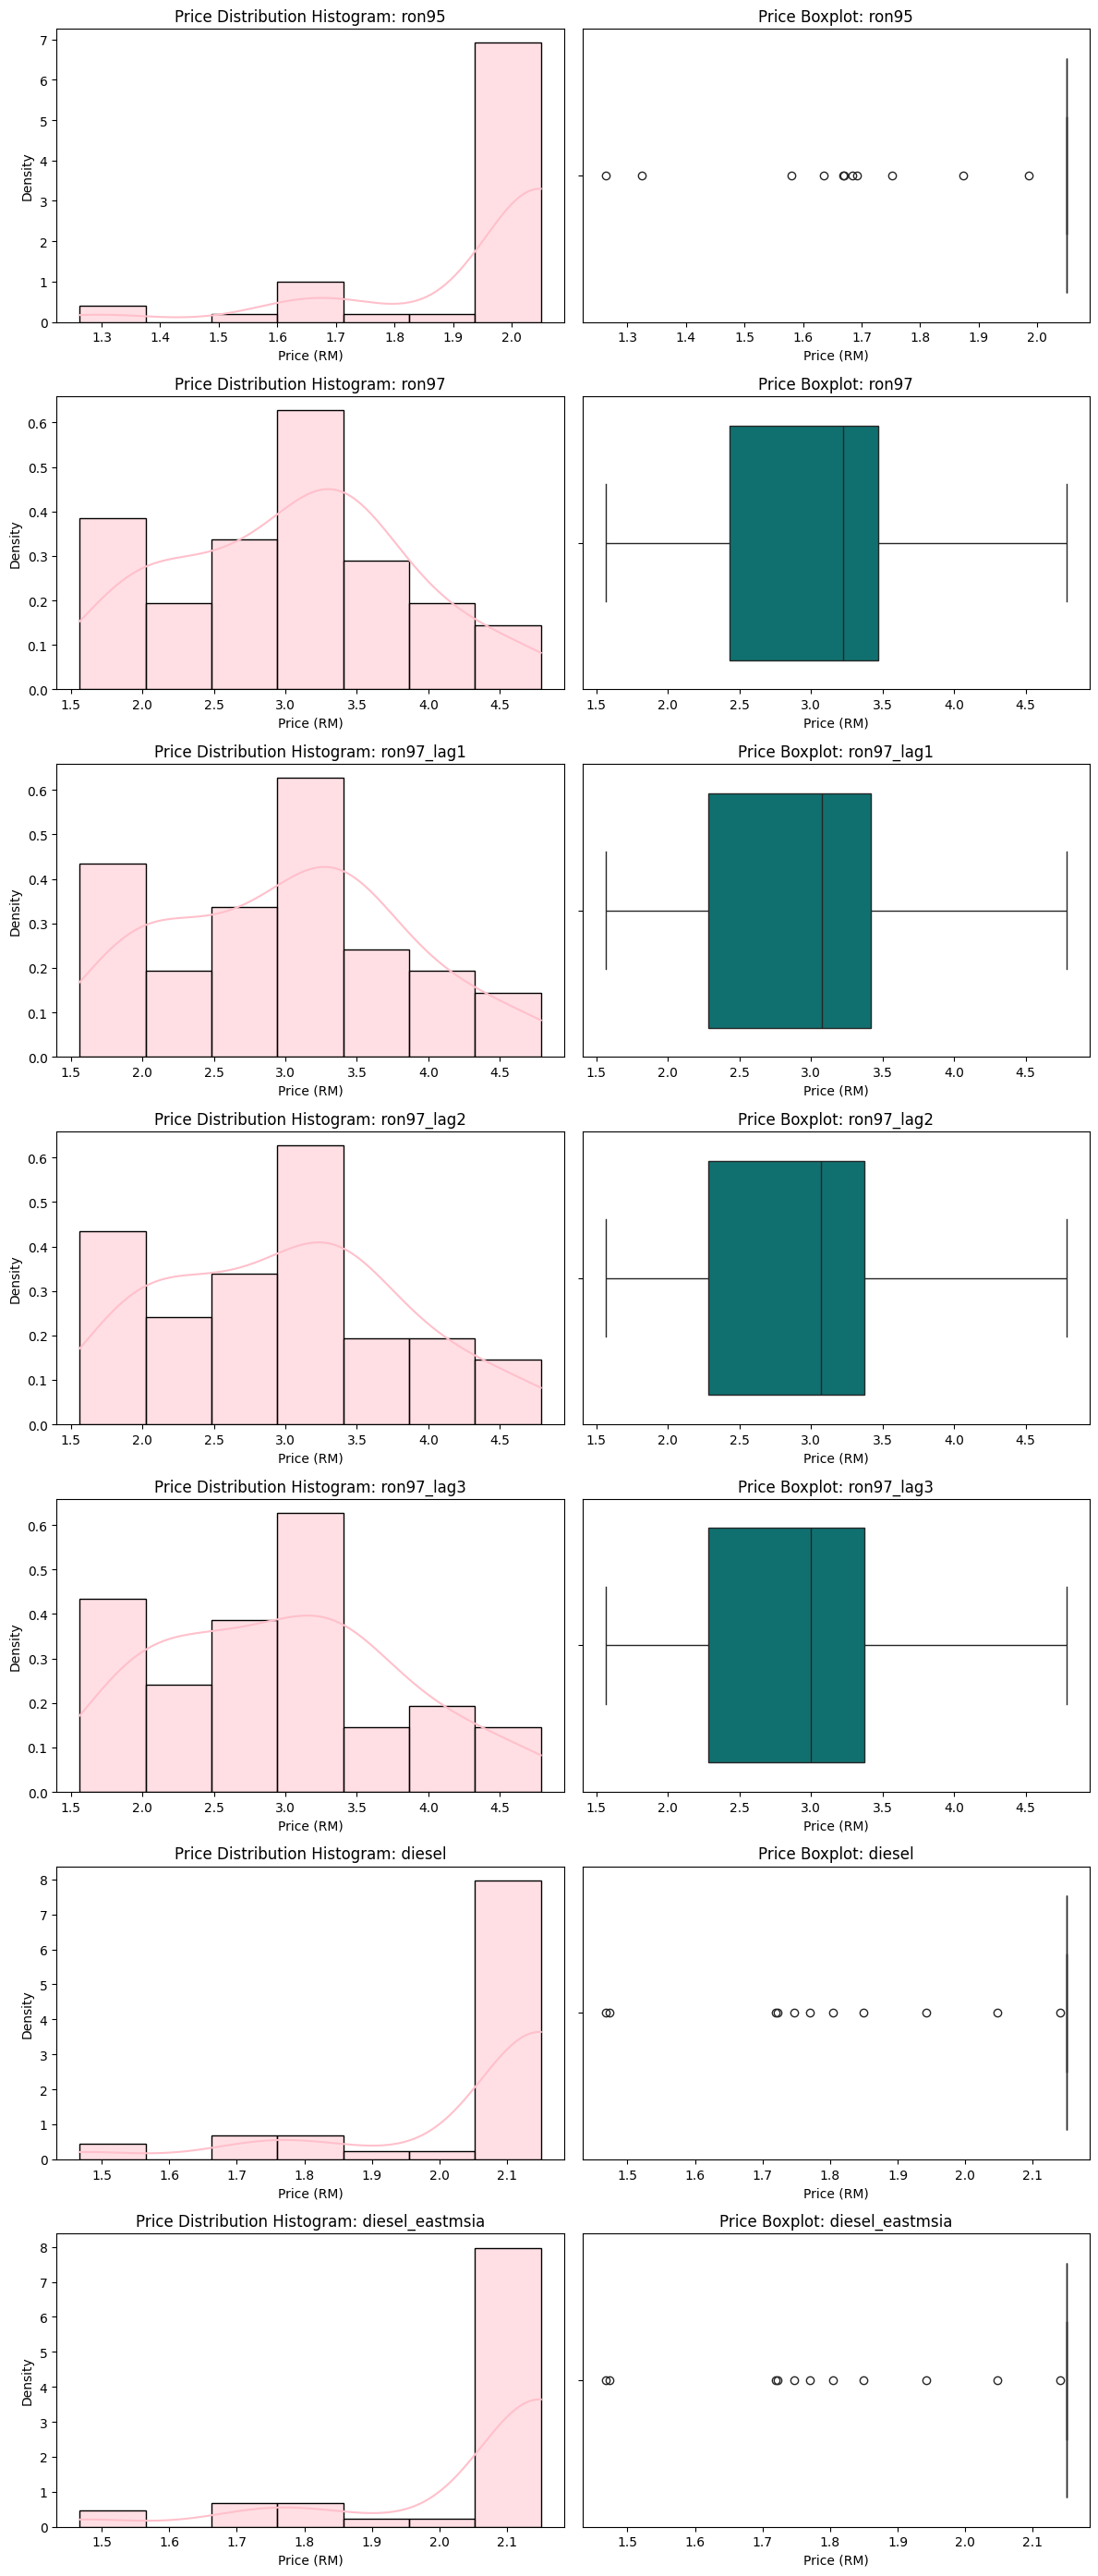

In [ ]:
num_rows = len(fuel_cols)
fig, axes = plt.subplots(num_rows, 2, figsize=(12, 4 * num_rows))

for i, col in enumerate(fuel_cols):
    # Left column: Histogram + KDE(Kernel Density Estimation)
    sns.histplot(df[col], kde=True, ax=axes[i, 0], color='pink', stat="density")
    axes[i, 0].set_title(f'Price Distribution Histogram: {col}')
    axes[i, 0].set_xlabel('Price (RM)')

    # Right column: Boxplot
    sns.boxplot(x=df[col], ax=axes[i, 1], color='teal')
    axes[i, 1].set_title(f'Price Boxplot: {col}')
    axes[i, 1].set_xlabel('Price (RM)')

plt.tight_layout()
plt.savefig('fuel_distributions.png', dpi=300)
plt.show()

### **Year-over-year Bar Chart**

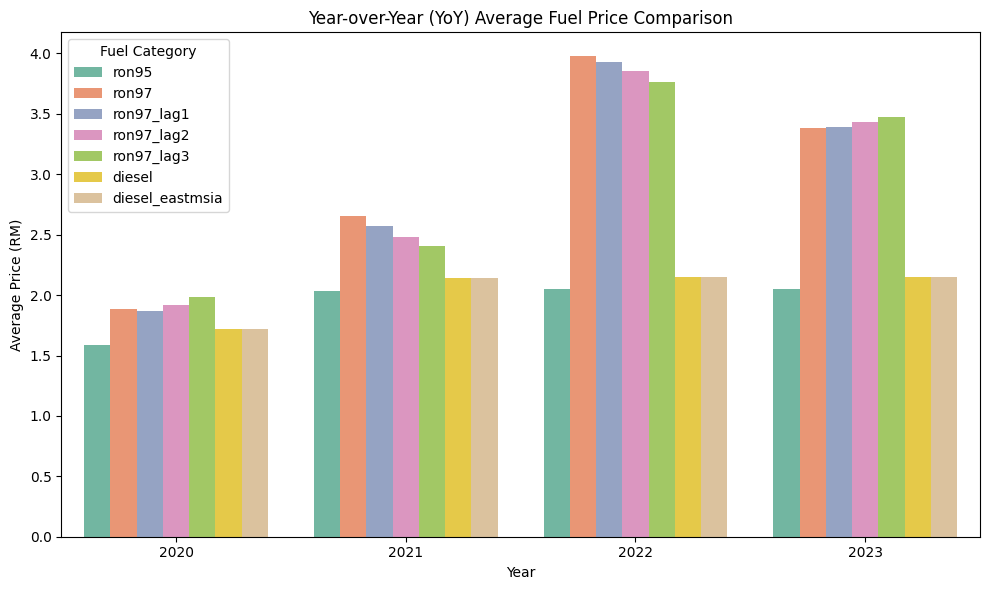

In [ ]:
df['year'] = df['date'].dt.year
yoy_df = df.groupby('year')[fuel_cols].mean().reset_index()

yoy_melted = yoy_df.melt(id_vars='year', value_vars=fuel_cols,
                         var_name='Fuel Type', value_name='Average Normalized Price')

plt.figure(figsize=(10, 6))
sns.barplot(data=yoy_melted, x='year', y='Average Normalized Price', hue='Fuel Type', palette='Set2')

plt.title('Year-over-Year (YoY) Average Fuel Price Comparison')
plt.xlabel('Year')
plt.ylabel('Average Price (RM)')
plt.legend(title='Fuel Category', loc='upper left')
plt.tight_layout()
plt.savefig('yoy_comparison.png', dpi=300)
plt.show()

- **Price of RON 95 stable** throughout the year due to government subsidies
- **Price of RON 97 spiked in 2022** due to post-pandemic economic shifts and Russia's invasion of Ukraine
- **Price of Diesel is consistent**. This is becuase, from 2020 until 2024, diesel's price is subsidies by the government.

**Summary of EDA :**

- RON97 price drops in April 2020 caused by global COVID-19 lockdowns. The lack of demands led to an unstable economic situation for the oil and gas industry
- Prices recovered sharply through 2021 and peaked in mid-2022 due to the Russia-Ukraine war, before entering a correction and stabilizing through 2023.

# **Section 4: Academic Baseline Evaluation**

In [ ]:
import numpy as np
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error, mean_absolute_error

df_arima = pd.read_csv(PROJECT_PATH + 'df_ron97_clean_newest.csv', parse_dates=['date'])
df_arima = df_arima.sort_values('date').reset_index(drop=True)

split_index_arima = int(len(df_arima) * 0.8)

ron97_series = df_arima['ron97'].values
train_arima  = ron97_series[:split_index_arima]
test_arima   = ron97_series[split_index_arima:]
dates_test_arima = df_arima['date'].iloc[split_index_arima:]

print(f"Train size: {len(train_arima)} months")
print(f"Test size:  {len(test_arima)} months")
print(f"Test period: {dates_test_arima.iloc[0].date()} to {dates_test_arima.iloc[-1].date()}")

arima_model    = ARIMA(train_arima, order=(1, 1, 1))
arima_fitted   = arima_model.fit()
arima_forecast = arima_fitted.forecast(steps=len(test_arima))

rmse_arima = np.sqrt(mean_squared_error(test_arima, arima_forecast))
mae_arima  = mean_absolute_error(test_arima, arima_forecast)
ss_res     = np.sum((test_arima - arima_forecast) ** 2)
ss_tot     = np.sum((test_arima - np.mean(test_arima)) ** 2)
r2_arima   = 1 - (ss_res / ss_tot)

print('\n' + '=' * 55)
print('  ARIMA(1,1,1) — Replicated Baseline')
print('=' * 55)
print(f'  RMSE : RM {rmse_arima:.4f}')
print(f'  MAE  : RM {mae_arima:.4f}')
print(f'  R²   :    {r2_arima:.4f}')
print('=' * 55)


Train size: 36 months
Test size:  9 months
Test period: 2023-04-30 to 2023-12-31

  ARIMA(1,1,1) — Replicated Baseline
  RMSE : RM 0.0654
  MAE  : RM 0.0468
  R²   :    -1.0913


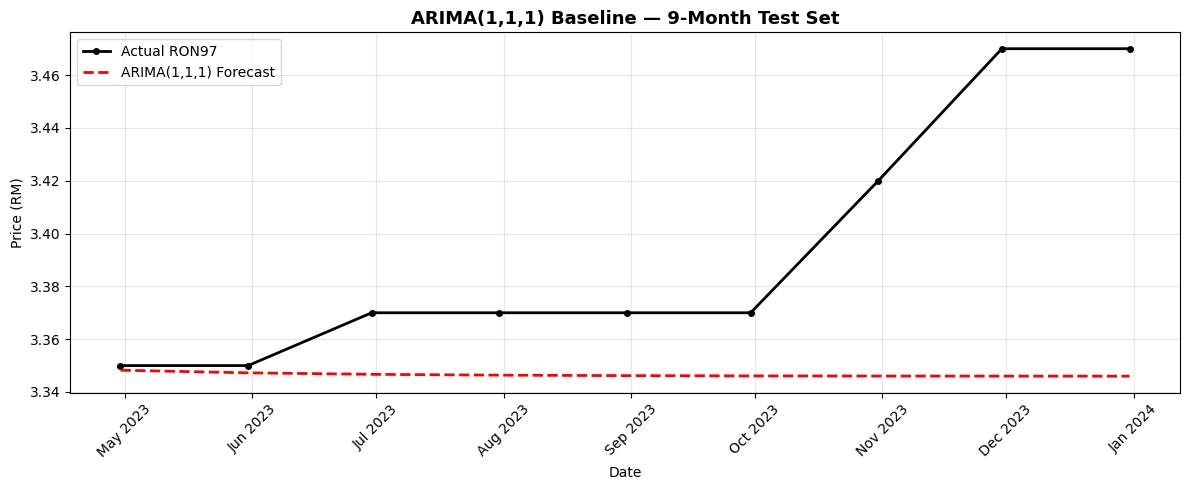

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.figure(figsize=(12, 5))
plt.plot(dates_test_arima, test_arima,
         label='Actual RON97', color='black',
         linewidth=2, marker='o', markersize=4)
plt.plot(dates_test_arima, arima_forecast,
         label='ARIMA(1,1,1) Forecast',
         color='red', linestyle='--', linewidth=2)
plt.title('ARIMA(1,1,1) Baseline — 9-Month Test Set',
          fontsize=13, fontweight='bold')
plt.ylabel('Price (RM)')
plt.xlabel('Date')
plt.legend()
plt.grid(True, alpha=0.3)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# **Section 5: Modelling Pipeline**

This section implements two supervised machine learning models — **Ridge Regression**
and **Support Vector Regression (SVR)** — across two experimental phases. Both models
are evaluated on an identical chronological 80/20 train/test split to ensure fair
comparison against the ARIMA(1,1,1) baseline.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

## 5.1 Data Ingestion & Temporal Partitioning

The cleaned dataset is loaded and partitioned chronologically. A strict 80/20 split
is applied, yielding approximately 36 training months and a 9-month holdout test set.
Random shuffling is deliberately avoided to preserve the temporal ordering of the
time series.

In [ ]:
df = pd.read_csv(PROJECT_PATH + 'df_ron97_clean_newest.csv', parse_dates=['date'])
df = df.sort_values('date').reset_index(drop=True)

TARGET = 'target_ron97_next_month'
SPLIT_IDX = int(len(df) * 0.8)
TSCV = TimeSeriesSplit(n_splits=3)

dates_test = df['date'].iloc[SPLIT_IDX:]

print(f"Training Set : {df['date'].iloc[0].date()} → {df['date'].iloc[SPLIT_IDX-1].date()} ({SPLIT_IDX} months)")
print(f"Test Set     : {df['date'].iloc[SPLIT_IDX].date()} → {df['date'].iloc[-1].date()} ({len(df)-SPLIT_IDX} months)")

Training Set : 2020-04-30 → 2023-03-31 (36 months)
Test Set     : 2023-04-30 → 2023-12-31 (9 months)


## 5.2 Shared Evaluation Framework

To ensure consistency across all models, a unified set of utility functions is defined
for metric computation and visualisation. All error metrics (RMSE, MAE, R²) are
reported in real Malaysian Ringgit (RM) on the unnormalised scale, matching the
ARIMA baseline replication in Section 4.

In [ ]:
def evaluate_model(y_true, y_pred, label):
    """Computes RMSE, MAE, and R² on the real RM scale."""
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)
    r2   = r2_score(y_true, y_pred)
    print(f"\n  Evaluation — {label}")
    print(f"  RMSE : RM {rmse:.4f}")
    print(f"  MAE  : RM {mae:.4f}")
    print(f"  R²   :    {r2:.4f}")
    return {'Label': label, 'RMSE': rmse, 'MAE': mae, 'R2': r2}


def plot_forecast(dates, y_true, y_pred, title, pred_label, color):
    """Generates a standardised actual vs. predicted forecast plot."""
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(dates, y_true, label='Actual RON97',
            color='black', linewidth=2, marker='o', markersize=4)
    ax.plot(dates, y_pred, label=pred_label,
            color=color, linestyle='--', linewidth=2, marker='s', markersize=4)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Date')
    ax.set_ylabel('Price (RM/litre)')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True, alpha=0.3)
    ax.legend(loc='best')
    plt.tight_layout()
    plt.savefig(f"{title.replace(' ', '_').replace(':', '')}.png", dpi=150)
    plt.show()


def print_comparison_table(results_list):
    """Prints a formatted comparison table against the ARIMA baseline."""
    col_w = 30
    print("\n" + "=" * 75)
    print(f"  {'Model':<{col_w}} {'RMSE (RM)':>10} {'MAE (RM)':>10} {'R²':>10}  {'vs. Baseline'}")
    print("-" * 75)
    print(f"  {'ARIMA(1,1,1) — Baseline':<{col_w}} {rmse_arima:>10.4f} {mae_arima:>10.4f} {r2_arima:>10.4f}")
    print("-" * 75)
    for r in results_list:
        flag = "OUTPERFORMS" if r['RMSE'] < rmse_arima else "Does not beat baseline"
        print(f"  {r['Label']:<{col_w}} {r['RMSE']:>10.4f} {r['MAE']:>10.4f} {r['R2']:>10.4f}  {flag}")
    print("=" * 75)

## 5.3 Phase 1: Univariate Models (RON97 Lags Only)

Phase 1 establishes a direct and fair comparison against the ARIMA(1,1,1) baseline
by restricting both models to the same autoregressive feature set: three one-month
lag variables (`ron97_lag1`, `ron97_lag2`, `ron97_lag3`). This isolates model
architecture as the sole differentiating factor.

### 5.3.1 Ridge Regression — Phase 1

Ridge Regression applies L2 regularisation to a linear model, penalising large
coefficients to reduce overfitting on the small 45-month dataset. The regularisation
strength (alpha) is tuned via GridSearchCV with TimeSeriesSplit cross-validation.


  Evaluation — Ridge Regression — Phase 1
  RMSE : RM 0.0358
  MAE  : RM 0.0261
  R²   :    0.4456


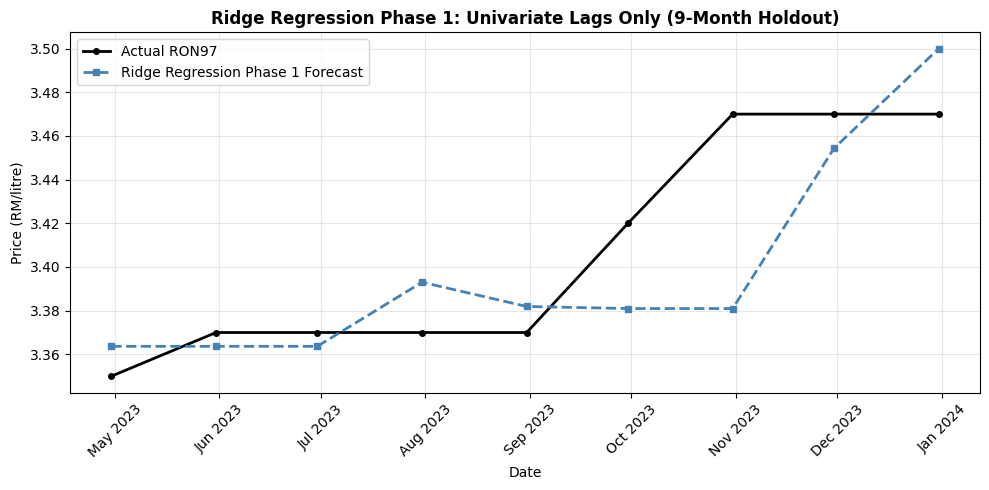

In [ ]:
# =============================================================================
# PHASE 1 — RIDGE REGRESSION: UNIVARIATE (RON97 LAGS ONLY)
# =============================================================================

FEATURES_P1 = ['ron97_lag1', 'ron97_lag2', 'ron97_lag3']

X_train_rr_p1 = df[FEATURES_P1].iloc[:SPLIT_IDX]
X_test_rr_p1  = df[FEATURES_P1].iloc[SPLIT_IDX:]
y_train_rr_p1 = df[TARGET].iloc[:SPLIT_IDX]
y_test_rr_p1  = df[TARGET].iloc[SPLIT_IDX:]

rr_grid_p1 = GridSearchCV(
    Ridge(),
    {'alpha': [0.01, 0.1, 1.0, 10.0, 100.0]},
    cv=TSCV, scoring='neg_mean_squared_error', n_jobs=-1
)
rr_grid_p1.fit(X_train_rr_p1, y_train_rr_p1)
y_pred_rr_p1 = rr_grid_p1.best_estimator_.predict(X_test_rr_p1)

results_rr_p1 = evaluate_model(y_test_rr_p1, y_pred_rr_p1, 'Ridge Regression — Phase 1')

plot_forecast(
    dates      = dates_test,
    y_true     = y_test_rr_p1.values,
    y_pred     = y_pred_rr_p1,
    title      = 'Ridge Regression Phase 1: Univariate Lags Only (9-Month Holdout)',
    pred_label = 'Ridge Regression Phase 1 Forecast',
    color      = 'steelblue'
)

### 5.3.2 Support Vector Regression (SVR) — Phase 1

SVR fits a hyperplane within an epsilon-insensitive margin, making it robust to
minor price fluctuations. The RBF and linear kernels are both evaluated, with the
optimal kernel, C, and epsilon selected via GridSearchCV.


  Evaluation — SVR — Phase 1
  RMSE : RM 0.0411
  MAE  : RM 0.0278
  R²   :    0.2675


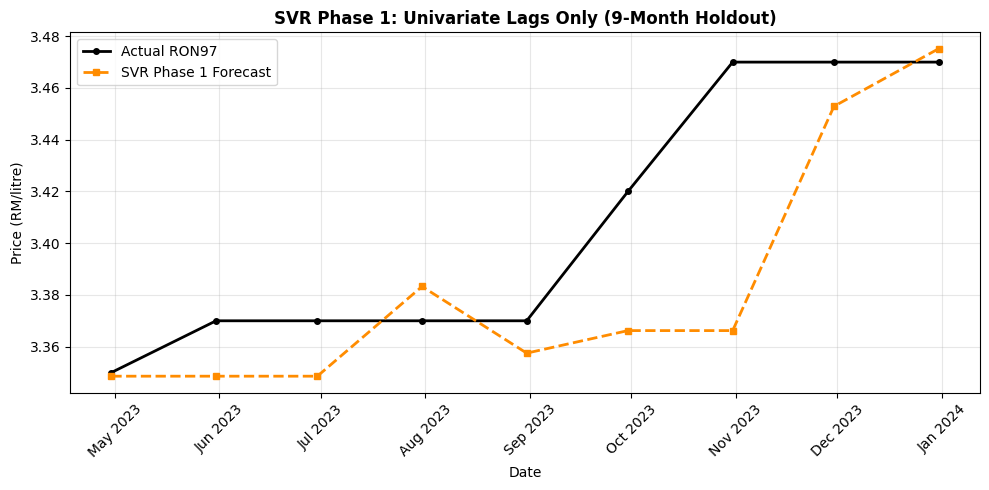

In [ ]:
# =============================================================================
# PHASE 1 — SVR: UNIVARIATE (RON97 LAGS ONLY)
# =============================================================================

svr_param_grid = {
    'kernel':  ['linear', 'rbf'],
    'C':       [0.1, 1, 10, 100],
    'epsilon': [0.01, 0.05, 0.1]
}

X_train_svr_p1 = df[FEATURES_P1].iloc[:SPLIT_IDX]
X_test_svr_p1  = df[FEATURES_P1].iloc[SPLIT_IDX:]
y_train_svr_p1 = df[TARGET].iloc[:SPLIT_IDX]
y_test_svr_p1  = df[TARGET].iloc[SPLIT_IDX:]

svr_grid_p1 = GridSearchCV(
    SVR(), svr_param_grid,
    cv=TSCV, scoring='neg_mean_squared_error', n_jobs=-1
)
svr_grid_p1.fit(X_train_svr_p1, y_train_svr_p1)
y_pred_svr_p1 = svr_grid_p1.best_estimator_.predict(X_test_svr_p1)

results_svr_p1 = evaluate_model(y_test_svr_p1, y_pred_svr_p1, 'SVR — Phase 1')

plot_forecast(
    dates      = dates_test,
    y_true     = y_test_svr_p1.values,
    y_pred     = y_pred_svr_p1,
    title      = 'SVR Phase 1: Univariate Lags Only (9-Month Holdout)',
    pred_label = 'SVR Phase 1 Forecast',
    color      = 'darkorange'
)

### Phase 1 Results Summary

The table below compares both Phase 1 models against the replicated ARIMA(1,1,1)
baseline on the identical 9-month holdout test set.

In [ ]:
# =============================================================================
# PHASE 1 RESULTS: BOTH MODELS VS. ARIMA BASELINE
# =============================================================================

print_comparison_table([results_rr_p1, results_svr_p1])


  Model                           RMSE (RM)   MAE (RM)         R²  vs. Baseline
---------------------------------------------------------------------------
  ARIMA(1,1,1) — Baseline            0.0654     0.0468    -1.0913
---------------------------------------------------------------------------
  Ridge Regression — Phase 1         0.0358     0.0261     0.4456  OUTPERFORMS
  SVR — Phase 1                      0.0411     0.0278     0.2675  OUTPERFORMS


## 5.4 Phase 2: Multivariate Models (Cross-Fuel Anchors)

Phase 2 extends the feature space by incorporating government-regulated fuel prices
(RON95 and Diesel) as macro-structural anchors. To prevent look-ahead leakage, both
variables are lagged by one month (`ron95_lag1`, `diesel_lag1`), ensuring that only
information available at prediction time is used. A separate dataframe is constructed
to preserve Phase 1 split integrity.

In [ ]:
df_p2 = df.copy()
df_p2['ron95_lag1']  = df_p2['ron95'].shift(1)
df_p2['diesel_lag1'] = df_p2['diesel'].shift(1)
df_p2 = df_p2.dropna(subset=['ron95_lag1', 'diesel_lag1']).reset_index(drop=True)

FEATURES_P2  = ['ron97_lag1', 'ron97_lag2', 'ron97_lag3', 'ron95_lag1', 'diesel_lag1']
SPLIT_IDX_P2 = int(len(df_p2) * 0.8)
dates_test_p2 = df_p2['date'].iloc[SPLIT_IDX_P2:]

print(f"Phase 2 Training Set : {df_p2['date'].iloc[0].date()} → {df_p2['date'].iloc[SPLIT_IDX_P2-1].date()}")
print(f"Phase 2 Test Set     : {df_p2['date'].iloc[SPLIT_IDX_P2].date()} → {df_p2['date'].iloc[-1].date()}")

Phase 2 Training Set : 2020-05-31 → 2023-03-31
Phase 2 Test Set     : 2023-04-30 → 2023-12-31


### 5.4.1 Ridge Regression — Phase 2

The Phase 2 Ridge model extends the Phase 1 feature set with the lagged cross-fuel
anchors. The same alpha grid and TimeSeriesSplit cross-validation procedure is applied.


  Evaluation — Ridge Regression — Phase 2
  RMSE : RM 0.0353
  MAE  : RM 0.0308
  R²   :    0.4619


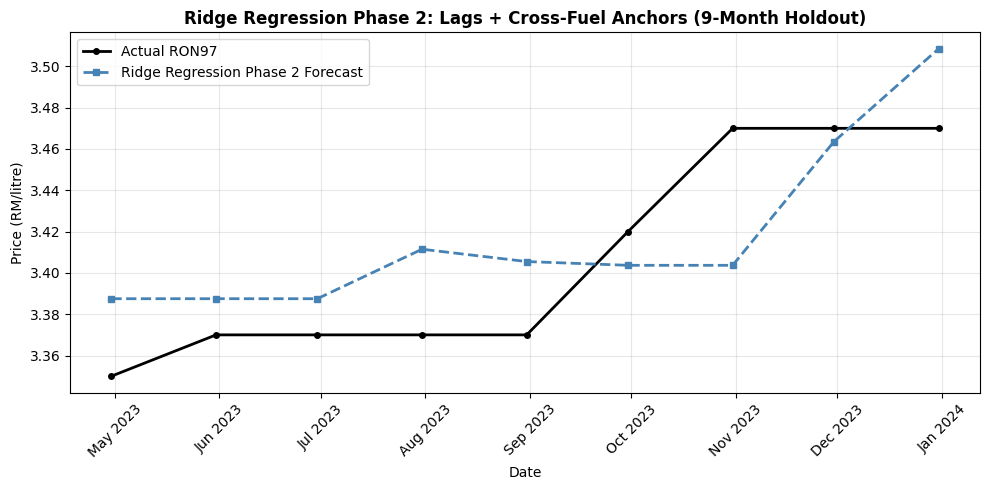

In [ ]:
# =============================================================================
# PHASE 2 — RIDGE REGRESSION: MULTIVARIATE (LAGS + CROSS-FUEL ANCHORS)
# =============================================================================

X_train_rr_p2 = df_p2[FEATURES_P2].iloc[:SPLIT_IDX_P2]
X_test_rr_p2  = df_p2[FEATURES_P2].iloc[SPLIT_IDX_P2:]
y_train_rr_p2 = df_p2[TARGET].iloc[:SPLIT_IDX_P2]
y_test_rr_p2  = df_p2[TARGET].iloc[SPLIT_IDX_P2:]

rr_grid_p2 = GridSearchCV(
    Ridge(),
    {'alpha': [0.01, 0.1, 1.0, 10.0, 100.0]},
    cv=TimeSeriesSplit(n_splits=3), scoring='neg_mean_squared_error', n_jobs=-1
)
rr_grid_p2.fit(X_train_rr_p2, y_train_rr_p2)
y_pred_rr_p2 = rr_grid_p2.best_estimator_.predict(X_test_rr_p2)

results_rr_p2 = evaluate_model(y_test_rr_p2, y_pred_rr_p2, 'Ridge Regression — Phase 2')

plot_forecast(
    dates      = dates_test_p2,
    y_true     = y_test_rr_p2.values,
    y_pred     = y_pred_rr_p2,
    title      = 'Ridge Regression Phase 2: Lags + Cross-Fuel Anchors (9-Month Holdout)',
    pred_label = 'Ridge Regression Phase 2 Forecast',
    color      = 'steelblue'
)

### 5.4.2 Support Vector Regression (SVR) — Phase 2

The Phase 2 SVR model is retrained on the expanded multivariate feature set. The
same hyperparameter grid is applied to allow a controlled comparison against the
Phase 1 SVR configuration.


  Evaluation — SVR — Phase 2
  RMSE : RM 0.0847
  MAE  : RM 0.0786
  R²   :    -2.1034


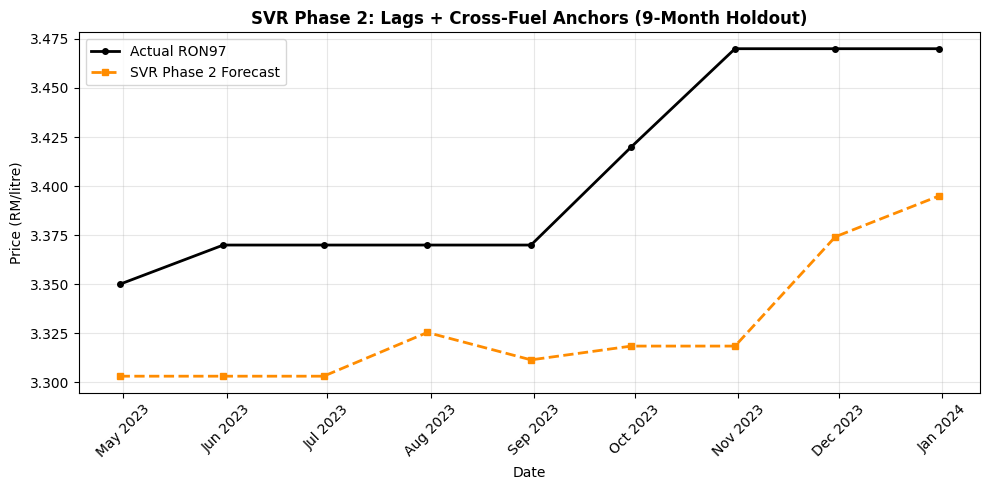

In [ ]:
# =============================================================================
# PHASE 2 — SVR: MULTIVARIATE (LAGS + CROSS-FUEL ANCHORS)
# =============================================================================

X_train_svr_p2 = df_p2[FEATURES_P2].iloc[:SPLIT_IDX_P2]
X_test_svr_p2  = df_p2[FEATURES_P2].iloc[SPLIT_IDX_P2:]
y_train_svr_p2 = df_p2[TARGET].iloc[:SPLIT_IDX_P2]
y_test_svr_p2  = df_p2[TARGET].iloc[SPLIT_IDX_P2:]

svr_grid_p2 = GridSearchCV(
    SVR(), svr_param_grid,
    cv=TimeSeriesSplit(n_splits=3), scoring='neg_mean_squared_error', n_jobs=-1
)
svr_grid_p2.fit(X_train_svr_p2, y_train_svr_p2)
y_pred_svr_p2 = svr_grid_p2.best_estimator_.predict(X_test_svr_p2)

results_svr_p2 = evaluate_model(y_test_svr_p2, y_pred_svr_p2, 'SVR — Phase 2')

plot_forecast(
    dates      = dates_test_p2,
    y_true     = y_test_svr_p2.values,
    y_pred     = y_pred_svr_p2,
    title      = 'SVR Phase 2: Lags + Cross-Fuel Anchors (9-Month Holdout)',
    pred_label = 'SVR Phase 2 Forecast',
    color      = 'darkorange'
)

# **Section 6: Benchmarking & Final Performance Evaluation**

## 6.1 Consolidated Performance Table

The table below presents the complete head-to-head comparison across all models.
The ARIMA(1,1,1) baseline serves as the performance floor — any model achieving a lower RMSE and MAE, as well as a higher R² value, is considered to have successfully outperformed the academic benchmark in terms of both predictive accuracy and explanatory power.

In [ ]:
print_comparison_table([
    results_rr_p1,
    results_rr_p2,
    results_svr_p1,
    results_svr_p2
])


  Model                           RMSE (RM)   MAE (RM)         R²  vs. Baseline
---------------------------------------------------------------------------
  ARIMA(1,1,1) — Baseline            0.0654     0.0468    -1.0913
---------------------------------------------------------------------------
  Ridge Regression — Phase 1         0.0358     0.0261     0.4456  OUTPERFORMS
  Ridge Regression — Phase 2         0.0353     0.0308     0.4619  OUTPERFORMS
  SVR — Phase 1                      0.0411     0.0278     0.2675  OUTPERFORMS
  SVR — Phase 2                      0.0847     0.0786    -2.1034  Does not beat baseline


## 6.2 Visual Comparison

The forecast plots below overlay all model predictions against the actual RON97
prices across the 9-month test period, providing a visual assessment of directional
accuracy and prediction bias.

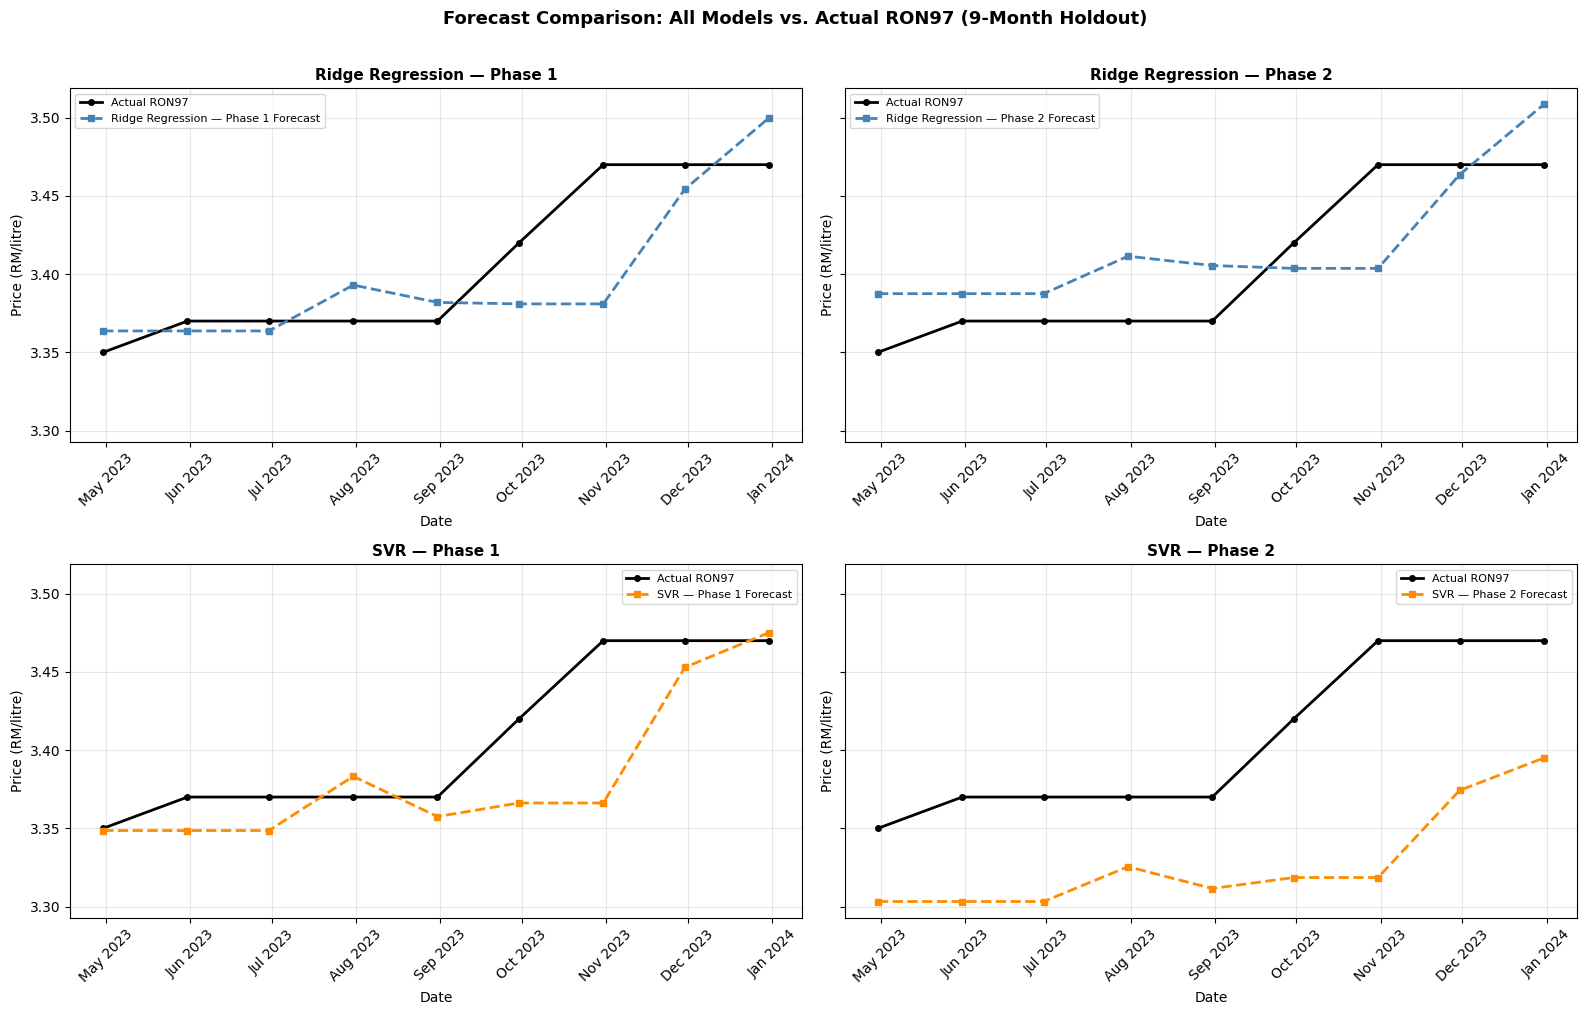

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharey=True)

configs = [
    (axes[0, 0], y_test_rr_p1.values,  y_pred_rr_p1,  dates_test,    'Ridge Regression — Phase 1',  'steelblue'),
    (axes[0, 1], y_test_rr_p2.values,  y_pred_rr_p2,  dates_test_p2, 'Ridge Regression — Phase 2',  'steelblue'),
    (axes[1, 0], y_test_svr_p1.values, y_pred_svr_p1, dates_test,    'SVR — Phase 1',               'darkorange'),
    (axes[1, 1], y_test_svr_p2.values, y_pred_svr_p2, dates_test_p2, 'SVR — Phase 2',               'darkorange'),
]

for ax, y_true, y_pred, dates, label, color in configs:
    ax.plot(dates, y_true, label='Actual RON97',
            color='black', linewidth=2, marker='o', markersize=4)
    ax.plot(dates, y_pred, label=f'{label} Forecast',
            color=color, linestyle='--', linewidth=2, marker='s', markersize=4)
    ax.set_title(label, fontsize=11, fontweight='bold')
    ax.set_ylabel('Price (RM/litre)')
    ax.set_xlabel('Date')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True, alpha=0.3)
    ax.legend(loc='best', fontsize=8)

plt.suptitle('Forecast Comparison: All Models vs. Actual RON97 (9-Month Holdout)',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('benchmark_comparison_all_models.png', dpi=150)
plt.show()

## 6.3 Feature Importance Analysis

This section investigates the contribution of each input feature in predicting RON97 fuel prices. Feature importance analysis helps identify which **lagged variables** have the **strongest influence on the model’s predictions**. Since this study uses both Ridge Regression and Support Vector Regression (SVR), two different interpretability methods are applied: coefficient-based importance for Ridge Regression and permutation-based importance for SVR. This allows for a more robust comparison of feature relevance across different modelling approaches.


Phase 1 Feature Importance (Normalised):
   Feature  Importance_Ridge  Importance_SVR
ron97_lag1          1.000000        1.000000
ron97_lag2          0.378078        0.198327
ron97_lag3          0.032673        0.014897


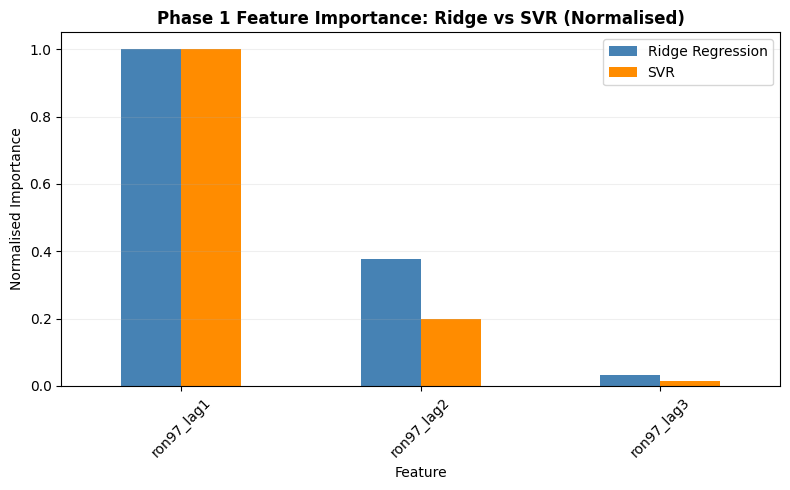

In [ ]:
# Ridge Phase 1 — coefficient-based importance
ridge_imp_p1 = pd.DataFrame({
    'Feature':    FEATURES_P1,
    'Importance': np.abs(rr_grid_p1.best_estimator_.coef_)
}).sort_values('Importance', ascending=False)

# SVR Phase 1 — permutation-based importance
perm_p1 = permutation_importance(
    svr_grid_p1.best_estimator_,
    X_test_svr_p1, y_test_svr_p1,
    n_repeats=10, random_state=42
)
svr_imp_p1 = pd.DataFrame({
    'Feature':    FEATURES_P1,
    'Importance': perm_p1.importances_mean
}).sort_values('Importance', ascending=False)

compare_p1 = pd.merge(ridge_imp_p1, svr_imp_p1, on='Feature', suffixes=('_Ridge', '_SVR'))
compare_p1['Importance_Ridge'] = compare_p1['Importance_Ridge'] / compare_p1['Importance_Ridge'].max()
compare_p1['Importance_SVR']   = compare_p1['Importance_SVR']   / compare_p1['Importance_SVR'].max()

print("Phase 1 Feature Importance (Normalised):")
print(compare_p1[['Feature', 'Importance_Ridge', 'Importance_SVR']].to_string(index=False))

compare_p1.set_index('Feature')[['Importance_Ridge', 'Importance_SVR']].plot(
    kind='bar', figsize=(8, 5), color=['steelblue', 'darkorange']
)
plt.title('Phase 1 Feature Importance: Ridge vs SVR (Normalised)', fontweight='bold')
plt.ylabel('Normalised Importance')
plt.xlabel('Feature')
plt.xticks(rotation=45)
plt.legend(['Ridge Regression', 'SVR'])
plt.grid(True, alpha=0.2, axis='y')
plt.tight_layout()
plt.savefig('feature_importance_phase1.png', dpi=150)
plt.show()

## Phase 1 Feature Importance

In Phase 1, the model utilises lagged RON97 values as predictors. The importance scores are normalised to allow direct comparison between Ridge Regression and SVR.

Both models consistently identify **RON97 lag-1** as the **most influential feature**. This indicates that the most recent previous month’s RON97 price is the **strongest predictor** of the current month’s price. This is expected in time-series forecasting, where recent observations typically carry the highest predictive power.

The second most important feature is RON97 lag-2, suggesting that the price from two months prior still contributes meaningful information to the prediction, although its influence is significantly weaker than lag-1. Meanwhile, RON97 lag-3 contributes minimally in both models, indicating that older historical values have limited predictive value in this dataset.

Phase 2 Feature Importance (Normalised):
    Feature  Importance_Ridge  Importance_SVR
 ron97_lag1          1.000000        1.000000
 ron97_lag2          0.249211        0.041040
diesel_lag1          0.191592        0.000000
 ron97_lag3          0.075929        0.038055
 ron95_lag1          0.041722        0.000000


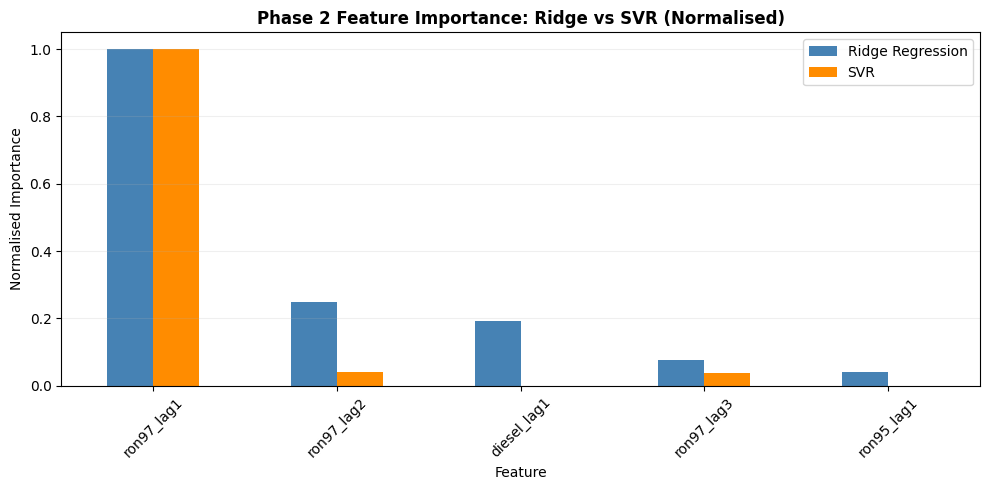

In [ ]:
# Ridge Phase 2 — coefficient-based importance
ridge_imp_p2 = pd.DataFrame({
    'Feature':    FEATURES_P2,
    'Importance': np.abs(rr_grid_p2.best_estimator_.coef_)
}).sort_values('Importance', ascending=False)

# SVR Phase 2 — permutation-based importance
perm_p2 = permutation_importance(
    svr_grid_p2.best_estimator_,
    X_test_svr_p2, y_test_svr_p2,
    n_repeats=10, random_state=42
)
svr_imp_p2 = pd.DataFrame({
    'Feature':    FEATURES_P2,
    'Importance': perm_p2.importances_mean
}).sort_values('Importance', ascending=False)

compare_p2 = pd.merge(ridge_imp_p2, svr_imp_p2, on='Feature', suffixes=('_Ridge', '_SVR'))
compare_p2['Importance_Ridge'] = compare_p2['Importance_Ridge'] / compare_p2['Importance_Ridge'].max()
compare_p2['Importance_SVR']   = compare_p2['Importance_SVR']   / compare_p2['Importance_SVR'].max()

print("Phase 2 Feature Importance (Normalised):")
print(compare_p2[['Feature', 'Importance_Ridge', 'Importance_SVR']].to_string(index=False))

compare_p2.set_index('Feature')[['Importance_Ridge', 'Importance_SVR']].plot(
    kind='bar', figsize=(10, 5), color=['steelblue', 'darkorange']
)
plt.title('Phase 2 Feature Importance: Ridge vs SVR (Normalised)', fontweight='bold')
plt.ylabel('Normalised Importance')
plt.xlabel('Feature')
plt.xticks(rotation=45)
plt.legend(['Ridge Regression', 'SVR'])
plt.grid(True, alpha=0.2, axis='y')
plt.tight_layout()
plt.savefig('feature_importance_phase2.png', dpi=150)
plt.show()

## Phase 2 Feature Importance

In Phase 2, additional fuel variables (RON95 and diesel lagged values) are introduced alongside RON97 lag features. The inclusion of these external variables allows the model to assess cross-fuel influence.

The results again show that **RON97 lag-1** remains the **most dominant feature** across both Ridge Regression and SVR, reinforcing the strong autoregressive nature of fuel prices.

In contrast, RON97 lag-2 retains moderate importance, while RON97 lag-3 shows reduced contribution, similar to Phase 1.

Interestingly, external fuel variables such as RON95 lag-1 and diesel lag-1 exhibit relatively **low importance** in Ridge Regression and are almost negligible in SVR. This suggests that while different fuel types may share general market trends, they do not significantly improve predictive performance compared to the historical values of RON97 itself.

## 6.4 Discussion

**Phase 1 Results**

* Both machine learning architectures **outperformed** the ARIMA(1,1,1) baseline using strictly past price lags.
* Crucially, both models yielded a **positive $R^2$ score**, proving genuine predictive power over the holdout test set where classical econometrics underperformed.

**Phase 2 Results**

* **Ridge Regression** achieved further improvement, successfully capturing a consistent linear signal from the heavily regulated fuel anchors (lagged RON95 and Diesel).
* **Support Vector Regression (SVR)** degraded severely, falling below the baseline. Because RON95 and Diesel prices were strictly controlled and exhibited near-zero variance, they acted as geometric noise, distorting the SVR margin optimization boundary.

**Best Performing Configuration:**

* **Ridge Regression (Phase 2)** is the optimal model overall, delivering the highest directional accuracy and lowest tracking error.

**Conclusion**

* **Hypothesis Validated:** Three out of four machine learning setups beat the traditional baseline, confirming the advantage of machine learning on this high-inertia dataset.
* **The SVR Limitation:** Kernel-based models are highly sensitive to feature geometry; adding low-variance, government-subsidized indicators introduces severe structural distortion.
* **Final Recommendation:** Regularized linear models provide a highly robust, interpretable, and accurate framework for forecasting government-adjacent retail fuel prices in Malaysia.